# 07. Error analysis: where does the forecast fail, and what drives accuracy?

The earlier notebooks show *how good* the forecast is. This one asks the questions a planner would
ask next:

1. **Where** is the error concentrated (which stores, which days)?
2. **How much does it shrink** if you plan weekly or for the whole chain instead of store by day?
3. **Which inputs matter?** Remove one group of features at a time and measure the damage.
4. **How much does fresher data help?** Forecast 7, 14, 28 or 42 days ahead and compare.

Sections 1 and 2 use the saved forecasts of all three windows. Sections 3 and 4 retrain the model
live on the final window.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rossmann_forecast.config import DEFAULT_ORIGINS, HORIZON, MIN_LAG
from rossmann_forecast.data import load_panel
from rossmann_forecast.metrics import all_metrics, wape
from rossmann_forecast.plotting import COLORS, NAMES, apply_style, find_root
from rossmann_forecast.splits import rolling_origin_folds

apply_style()
ROOT = find_root()
panel = load_panel(ROOT / "data")
folds = rolling_origin_folds(DEFAULT_ORIGINS, HORIZON, panel.dates[-1])
final_fold = folds[-1]
print(f"{len(panel.stores):,} stores, {panel.dates[0].date()} to {panel.dates[-1].date()}")

1,115 stores, 2013-01-01 to 2015-07-31


In [2]:
from rossmann_forecast.viz_data import load_forecasts

fc = load_forecasts(ROOT / "reports" / "viz_data")
fc["ae"] = (fc["y"] - fc["lightgbm"]).abs()
static = panel.static[["StoreType", "Assortment", "CompetitionDistance"]].rename_axis("store_id")
fc = fc.merge(static, left_on="store_id", right_index=True, how="left")
overall = fc["ae"].sum() / fc["y"].sum()
print(f"{len(fc):,} scored store-days over 3 windows, overall WAPE {overall:.1%}")

106,153 scored store-days over 3 windows, overall WAPE 9.3%


## 1. Where is the error concentrated?

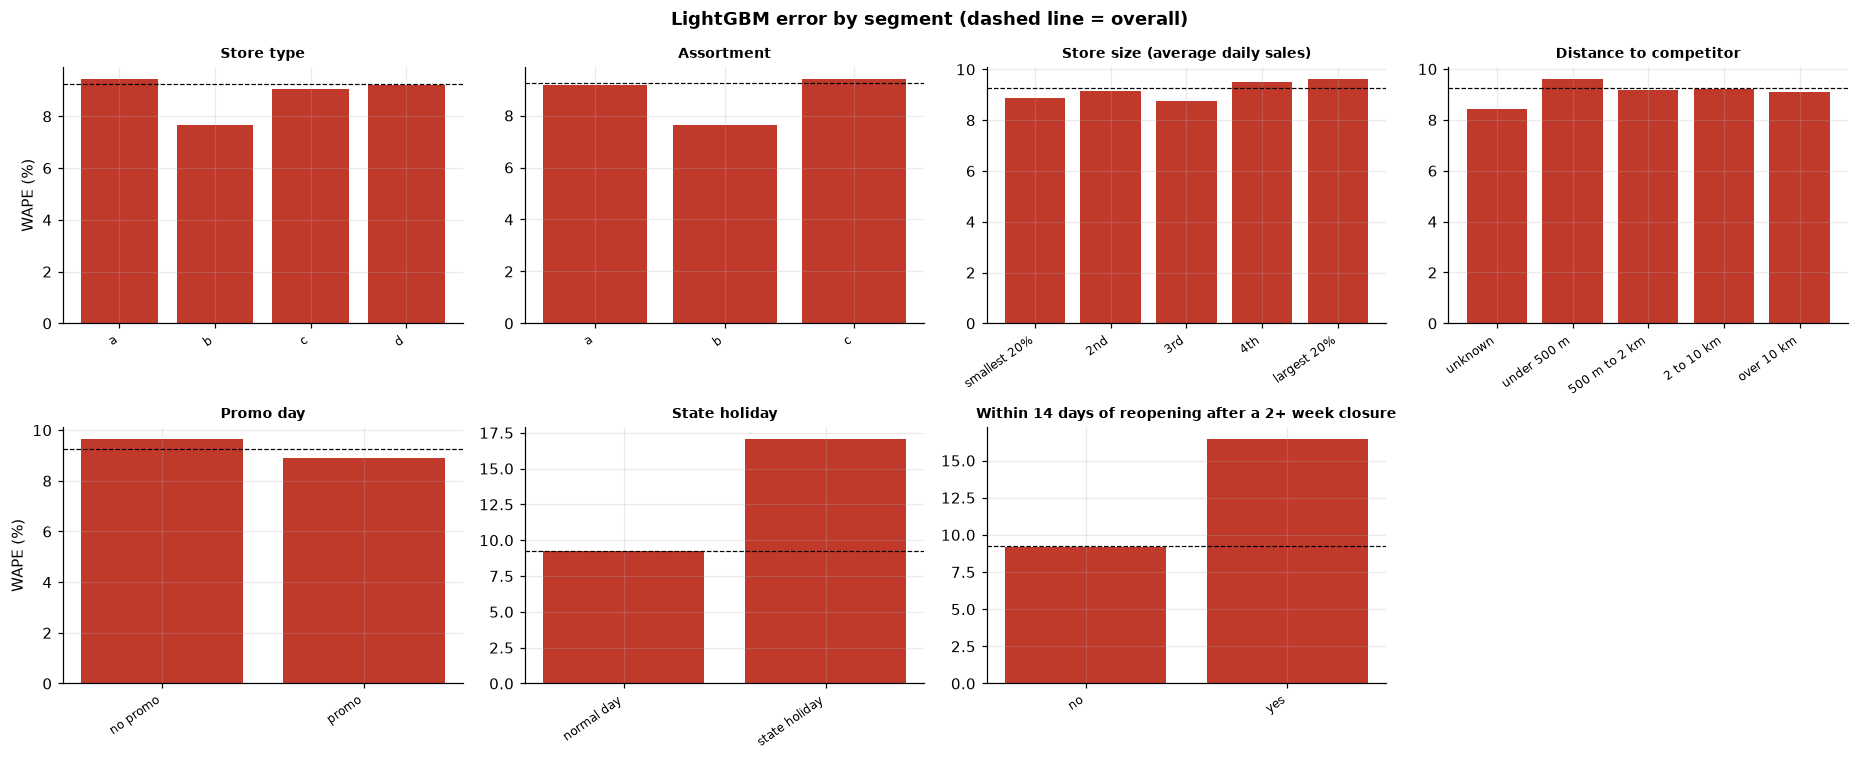

WAPE %  \
segment                                            group                   
Store type                                         a                 9.4   
                                                   b                 7.7   
                                                   c                 9.1   
                                                   d                 9.2   
Assortment                                         a                 9.2   
                                                   b                 7.6   
                                                   c                 9.4   
Store size (average daily sales)                   smallest 20%      8.9   
                                                   2nd               9.2   
                                                   3rd               8.7   
                                                   4th               9.5   
                                                   largest 20%       9.6   
Distance to competitor                             unknown           8.4   
                                                   under 500 m       9.6   
                                                   500 m to 2 km     9.2   
                                                   2 to 10 km        9.2   
                                                   over 10 km        9.1   
Promo day                                          no promo          9.6   
                                                   promo             8.9   
State holiday                                      normal day        9.3   
                                                   state holiday    17.0   
Within 14 days of reopening after a 2+ week clo... no                9.2   
                                                   yes              16.4   

                                                                  store-days  
segment                                            group                      
Store type                                         a                   57991  
                                                   b                    2069  
                                                   c                   14612  
                                                   d                   31481  
Assortment                                         a                   55116  
                                                   b                    1061  
                                                   c                   49976  
Store size (average daily sales)                   smallest 20%        21234  
                                                   2nd                 21232  
                                                   3rd                 21230  
                                                   4th                 21241  
                                                   largest 20%         21216  
Distance to competitor                             unknown               253  
                                                   under 500 m         21684  
                                                   500 m to 2 km       26237  
                                                   2 to 10 km          39959  
                                                   over 10 km          18020  
Promo day                                          no promo            59933  
                                                   promo               46220  
State holiday                                      normal day         106097  
                                                   state holiday          56  
Within 14 days of reopening after a 2+ week clo... no                 104774  
                                                   yes                  1379

In [3]:
def wape_by(frame, key):
    g = frame.groupby(key, observed=True)
    out = pd.DataFrame({"WAPE %": g["ae"].sum() / g["y"].sum() * 100, "store-days": g.size()})
    return out

fc["promo_day"] = panel.promo.stack().reindex(pd.MultiIndex.from_arrays([fc["date"], fc["store_id"]])).to_numpy()
fc["state_holiday"] = (panel.state_holiday.stack().reindex(pd.MultiIndex.from_arrays([fc["date"], fc["store_id"]])).to_numpy() > 0)
store_mean = fc.groupby(["fold", "store_id"])["y"].transform("mean")
fc["volume"] = pd.qcut(store_mean, 5, labels=["smallest 20%", "2nd", "3rd", "4th", "largest 20%"])
fc["competition"] = pd.cut(fc["CompetitionDistance"].fillna(-1), [-2, 0, 500, 2000, 10000, 1e9],
                           labels=["unknown", "under 500 m", "500 m to 2 km", "2 to 10 km", "over 10 km"])

# stores that just reopened after a gap of two weeks or more
valid = panel.sales.notna().to_numpy()
pos = np.arange(valid.shape[0])[:, None]
last_open = np.maximum.accumulate(np.where(valid, pos, -1), axis=0)
prev_open = np.vstack([np.full((1, valid.shape[1]), -1), last_open[:-1]])
gap = np.where(valid & (prev_open >= 0), pos - prev_open, 0)
reopen_pos = np.maximum.accumulate(np.where(gap >= 14, pos, -1), axis=0)
since = pos - reopen_pos
reopened = pd.DataFrame(valid & (reopen_pos >= 0) & (since < 14), index=panel.dates, columns=panel.stores)
fc["just_reopened"] = reopened.stack().reindex(pd.MultiIndex.from_arrays([fc["date"], fc["store_id"]])).to_numpy()

tables = {
    "Store type": wape_by(fc, "StoreType"),
    "Assortment": wape_by(fc, "Assortment"),
    "Store size (average daily sales)": wape_by(fc, "volume"),
    "Distance to competitor": wape_by(fc, "competition"),
    "Promo day": wape_by(fc, "promo_day").rename(index={False: "no promo", True: "promo"}),
    "State holiday": wape_by(fc, "state_holiday").rename(index={False: "normal day", True: "state holiday"}),
    "Within 14 days of reopening after a 2+ week closure": wape_by(fc, "just_reopened").rename(index={False: "no", True: "yes"}),
}
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (title, t) in zip(axes.ravel(), tables.items(), strict=False):
    ax.bar([str(i) for i in t.index], t["WAPE %"], color=COLORS["lightgbm"])
    ax.axhline(overall * 100, color="black", ls="--", lw=0.8)
    ax.set_title(title, fontsize=9)
    ax.tick_params(axis="x", labelrotation=35, labelsize=8)
    for lab in ax.get_xticklabels():
        lab.set_ha("right")
axes.ravel()[-1].axis("off")
axes[0, 0].set_ylabel("WAPE (%)")
axes[1, 0].set_ylabel("WAPE (%)")
fig.suptitle("LightGBM error by segment (dashed line = overall)", fontweight="bold")
fig.tight_layout()
plt.show()
pd.concat({k: v.round(1) for k, v in tables.items()}).rename_axis(["segment", "group"])

## 2. Planning at a coarser level cuts the error

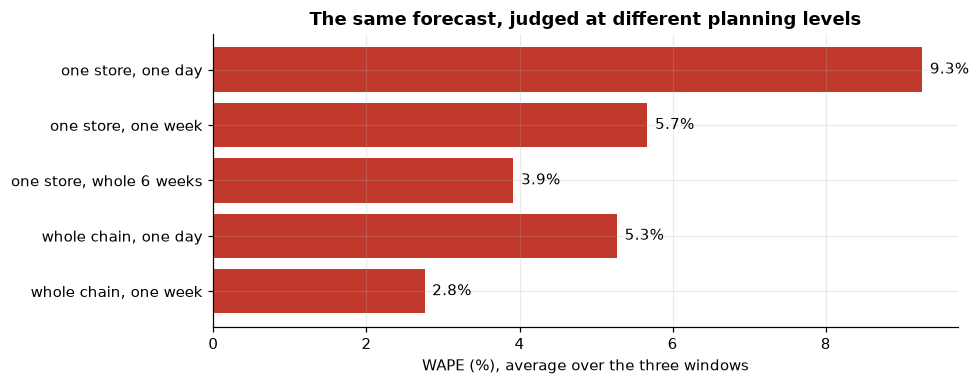

In [4]:
def level_wape(frame, keys, block=None):
    d = frame.copy()
    if block:
        d["block"] = ((d["date"] - d.groupby("fold")["date"].transform("min")).dt.days // block)
        keys = [*keys, "block"]
    g = d.groupby(["fold", *keys]).agg(y=("y", "sum"), p=("lightgbm", "sum"))
    return float((g["y"] - g["p"]).abs().sum() / g["y"].sum() * 100)

levels = {
    "one store, one day": level_wape(fc, ["store_id", "date"]),
    "one store, one week": level_wape(fc, ["store_id"], block=7),
    "one store, whole 6 weeks": level_wape(fc, ["store_id"], block=42),
    "whole chain, one day": level_wape(fc, ["date"]),
    "whole chain, one week": level_wape(fc, [], block=7),
}
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(list(levels)[::-1], list(levels.values())[::-1], color=COLORS["lightgbm"])
for i, v in enumerate(list(levels.values())[::-1]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center")
ax.set_xlabel("WAPE (%), average over the three windows")
ax.set_title("The same forecast, judged at different planning levels")
fig.tight_layout()
plt.show()

Daily store-level noise averages out. A weekly staffing plan or a chain-level stock order is
therefore forecast far more accurately than any single store-day.

## 3. Which inputs matter? Remove one feature group at a time

Each row retrains the LightGBM model without one group of features and scores it on the final
window. A bigger increase in error means the group matters more. (One window, one run per row, so
small differences are noise.)

8 models trained in 108 s


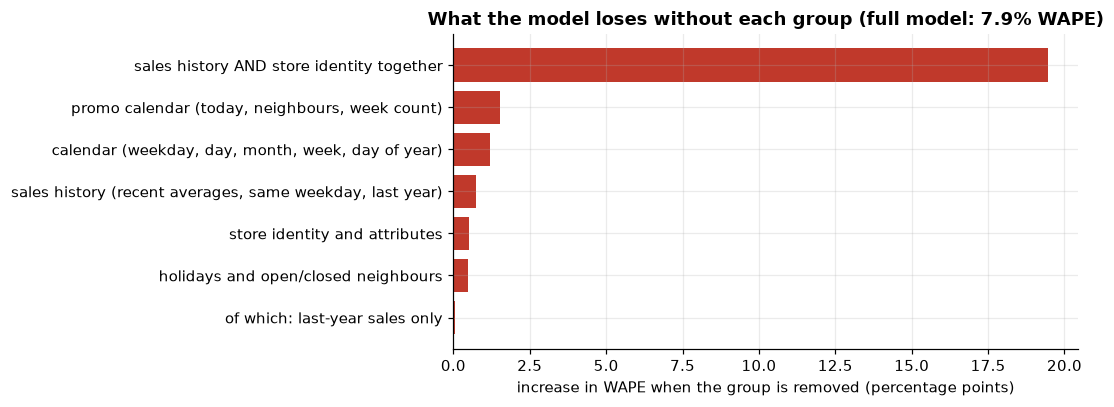

,WAPE %,increase vs full model (points)
removed,,
nothing (full model),7.94,0.00
"sales history (recent averages, same weekday, last year)",8.69,0.75
of which: last-year sales only,8.00,0.06
"promo calendar (today, neighbours, week count)",9.48,1.54
store identity and attributes,8.44,0.50
"calendar (weekday, day, month, week, day of year)",9.14,1.20
holidays and open/closed neighbours,8.41,0.47
sales history AND store identity together,27.41,19.47


In [5]:
import time

from rossmann_forecast.features import build_features
from rossmann_forecast.models import fit_lightgbm, forecast_rows, training_rows

origin = final_fold.test_start
feats = build_features(panel, MIN_LAG, known_until=origin)
train = training_rows(feats, origin)
test = forecast_rows(feats, origin, final_fold.test_end)
test = test[test["sales"].notna()]

groups = {
    "sales history (recent averages, same weekday, last year)": [c for c in train.columns if c.startswith(("roll", "dow_", "ly_", "promo_ratio"))],
    "of which: last-year sales only": ["ly_364", "ly_mean3"],
    "promo calendar (today, neighbours, week count)": ["promo", "promo_prev", "promo_next", "promo_7d"],
    "store identity and attributes": ["store", "store_type", "assortment", "comp_distance", "comp_open_months", "promo2_active"],
    "calendar (weekday, day, month, week, day of year)": ["dow", "day", "month", "week", "doy"],
    "holidays and open/closed neighbours": ["school_holiday", "state_holiday", "holiday_prev", "holiday_next", "open_prev", "open_next"],
}
rows = []
t0 = time.time()
base_model = fit_lightgbm(train)
base = wape(test["sales"], base_model.predict(test)) * 100
rows.append({"removed": "nothing (full model)", "WAPE %": base})
groups["sales history AND store identity together"] = groups["sales history (recent averages, same weekday, last year)"] + groups["store identity and attributes"]
for name, cols in groups.items():
    keep = train.drop(columns=cols)
    m = fit_lightgbm(keep)
    rows.append({"removed": name, "WAPE %": wape(test["sales"], m.predict(test)) * 100})
ablation = pd.DataFrame(rows).set_index("removed")
ablation["increase vs full model (points)"] = ablation["WAPE %"] - base
print(f"{len(rows)} models trained in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(10, 3.8))
plot = ablation.iloc[1:].sort_values("increase vs full model (points)")
ax.barh(plot.index, plot["increase vs full model (points)"], color=COLORS["lightgbm"])
ax.set_xlabel("increase in WAPE when the group is removed (percentage points)")
ax.set_title(f"What the model loses without each group (full model: {base:.1f}% WAPE)")
fig.tight_layout()
plt.show()
ablation.round(2)

Reading it: the **promo calendar** is the single most valuable group, followed by the weekday and
calendar features. Removing the sales-history features alone costs less than you might expect,
because the model can still learn each store's typical level from its identity. The last row
removes both at once and shows the combined loss, so the two groups overlap rather than one being
useless. Last-year sales add almost nothing once the other history features are present.

## 4. How much does fresher data help?

The main results forecast every day 42 days ahead. If the forecast were refreshed more often,
each day would be predicted from newer sales. Here every day of the final window is forecast
**L days ahead** (features use only sales up to L days earlier) for L = 7, 14, 28 and 42, with the
model trained only on data before the window.

4 models trained in 68 s


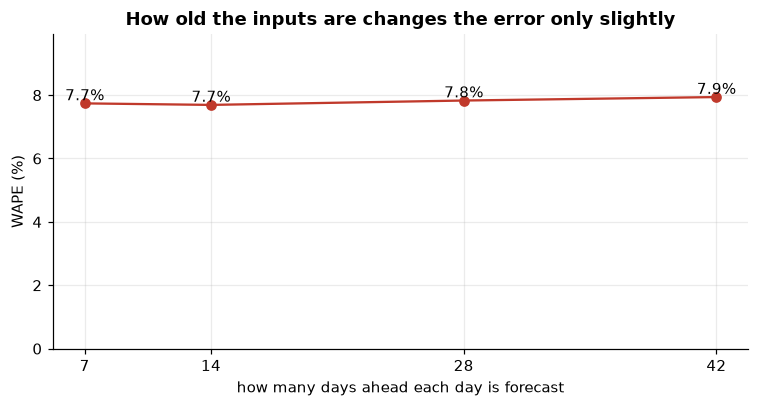

,WAPE %
days ahead,
7,7.74
14,7.69
28,7.83
42,7.94


In [6]:
rows = []
t0 = time.time()
for lag in [7, 14, 28, 42]:
    feats_l = build_features(panel, lag)  # features for day t read sales up to t - lag, nothing newer
    train_l = training_rows(feats_l, origin)  # labels strictly before the window
    test_l = forecast_rows(feats_l, origin, final_fold.test_end)
    test_l = test_l[test_l["sales"].notna()]
    model_l = fit_lightgbm(train_l)
    rows.append({"days ahead": lag, "WAPE %": wape(test_l["sales"], model_l.predict(test_l)) * 100})
fresh = pd.DataFrame(rows).set_index("days ahead")
print(f"4 models trained in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(fresh.index, fresh["WAPE %"], "o-", color=COLORS["lightgbm"])
for lag, v in fresh["WAPE %"].items():
    ax.text(lag, v + 0.1, f"{v:.1f}%", ha="center")
ax.set_xticks(fresh.index)
ax.set_xlabel("how many days ahead each day is forecast")
ax.set_ylabel("WAPE (%)")
ax.set_title("How old the inputs are changes the error only slightly")
ax.set_ylim(0, fresh["WAPE %"].max() * 1.25)
fig.tight_layout()
plt.show()
fresh.round(2)

## Key findings (computed from the cells above)

In [7]:
seg = tables
best_type = seg["Store type"]["WAPE %"].idxmin(), seg["Store type"]["WAPE %"].min()
worst_type = seg["Store type"]["WAPE %"].idxmax(), seg["Store type"]["WAPE %"].max()
reo = seg["Within 14 days of reopening after a 2+ week closure"]["WAPE %"]
share_reopen = tables["Within 14 days of reopening after a 2+ week closure"].loc["yes", "store-days"] / len(fc) * 100
drops = ablation.drop(index=["nothing (full model)", "of which: last-year sales only", "sales history AND store identity together"])
top = drops.loc[drops["increase vs full model (points)"].idxmax()]
hist = ablation.loc["sales history (recent averages, same weekday, last year)"]
both = ablation.loc["sales history AND store identity together"]
lines = [
    f"* Overall store-day WAPE is {overall:.1%}. By store type it ranges from {best_type[1]:.1f}% (type {best_type[0]}) to {worst_type[1]:.1f}% (type {worst_type[0]}).",
    f"* Store-days within 14 days of reopening after a long closure are only {share_reopen:.1f}% of rows but have WAPE {reo['yes']:.1f}% against {reo['no']:.1f}% for the rest.",
    f"* Planning weekly instead of daily cuts the store-level error from {levels['one store, one day']:.1f}% to {levels['one store, one week']:.1f}%; for the whole chain by week it is {levels['whole chain, one week']:.1f}%.",
    f"* Removing a feature group (full model {base:.1f}% WAPE): the biggest loss from removing one group is '{top.name}' at +{top['increase vs full model (points)']:.2f} points; "
    f"sales history alone costs +{hist['increase vs full model (points)']:.2f}, but history and store identity together cost +{both['increase vs full model (points)']:.2f}.",
    f"* Forecasting 7 days ahead gives {fresh.loc[7, 'WAPE %']:.1f}% against {fresh.loc[42, 'WAPE %']:.1f}% at 42 days ahead, a gain of only {fresh.loc[42, 'WAPE %'] - fresh.loc[7, 'WAPE %']:.2f} points.",
    f"* Error is fairly even across store type, size and competition distance (store-type range {best_type[1]:.1f}% to {worst_type[1]:.1f}%); the sharp exceptions are reopened stores and state holidays ({tables['State holiday'].loc['state holiday', 'store-days']:,.0f} store-days at {tables['State holiday'].loc['state holiday', 'WAPE %']:.1f}%).",
]
print("\n".join(lines))

* Overall store-day WAPE is 9.3%. By store type it ranges from 7.7% (type b) to 9.4% (type a).
* Store-days within 14 days of reopening after a long closure are only 1.3% of rows but have WAPE 16.4% against 9.2% for the rest.
* Planning weekly instead of daily cuts the store-level error from 9.3% to 5.7%; for the whole chain by week it is 2.8%.
* Removing a feature group (full model 7.9% WAPE): the biggest loss from removing one group is 'promo calendar (today, neighbours, week count)' at +1.54 points; sales history alone costs +0.75, but history and store identity together cost +19.47.
* Forecasting 7 days ahead gives 7.7% against 7.9% at 42 days ahead, a gain of only 0.20 points.
* Error is fairly even across store type, size and competition distance (store-type range 7.7% to 9.4%); the sharp exceptions are reopened stores and state holidays (56 store-days at 17.0%).


Practical reading: a six-week-ahead forecast is almost as good as a one-week-ahead one, so there is
little to gain from refreshing it more often; the planned promo calendar is what the forecast
needs most, so keep it current; stores that just reopened after a long closure need separate
handling because their own history misleads the model; and the most dependable numbers are at
weekly or chain level.

Limitations: sections 3 and 4 use one window and one training run each, so differences of a few
tenths of a point are within noise (the 7 to 42 day gap is of that size). Sections 1 and 2 use all
three windows. State holidays are only a handful of store-days, so that figure is rough.